In [18]:
import time
import h5py

import numpy as np
import matplotlib.pyplot as plt
import sys
import inspect

sys.path.append('/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/')
from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.integrating import Integrating
from chemrixs.process import Reduced
from chemrixs.utils import *
from pathlib import Path
%matplotlib widget 

### Incident Energy Calibration
- I understand that within EPICS there should already be a variable that I can just scan over to give MONO energies
- I can also undergo the hrencoder calibration with mirror and grating pitch values to yield more accurate reults?
- Bin the resulting shots into energy bins

In [40]:
# --- config ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 250           
bgrun = 86  
runs = [112,114,115]

base_folder =  '/sdf/data/lcls/ds/rix/'
proc_folder = './proc/'


fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
bgname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{bgrun:04d}.h5'

fyaml = '../roi_input.yml'   
calib_yaml = '../mono_calib.yml'
bgyaml = '../BGroi_input.yml'          

In [41]:
small_data = SmallData(fname, fyaml)
axis_svls = small_data.integrating.axis_svls

for k, v in vars(axis_svls).items():
    print(f"{k:30s} {type(v).__name__:12s} {getattr(v, 'shape', '')}")

250
setting up properties
dataset prop <functools.cached_property object at 0x7f46f4a56cd0>
dataset prop <functools.cached_property object at 0x7f46f621ecd0>
dataset prop <functools.cached_property object at 0x7f46f4798150>
dataset prop <functools.cached_property object at 0x7f46f6219490>
dataset prop <functools.cached_property object at 0x7f46f61b2150>
dataset prop <functools.cached_property object at 0x7f46f6282550>
dataset prop <functools.cached_property object at 0x7f46f4897650>
dataset prop <functools.cached_property object at 0x7f46f6362850>
grp                            Group        
chunks                         str          
mono_encoder                   ndarray      (15716,)
count                          ndarray      (15716,)
mono                           ndarray      (15716,)
full_area                      ndarray      (15716, 796)
eventcodes                     ndarray      (15716, 288)
piranha                        ndarray      (15716, 2048)
apd                      

In [ ]:
avg = Average(runs, proc_path = 'proc/Run', avg = 'mean', output_path = f'avg/{runs[0]}_to_{runs[-1]}.h5',
             raw_path = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run' , bgpath = bgname, fyaml=fyaml, bgyaml=bgyaml, 
             save= True,norm = True)


svls = avg.average

for k in svls.keys():
    print(f"{k:30s} {type(svls[k]).__name__:12s} {getattr(svls[k], 'shape', '')}")

[112. 193. 202. 202. 202. 208. 209. 200. 202. 196. 206. 199. 197. 207.
 205. 205. 208. 197. 201. 203. 197. 195. 200. 206. 205. 189. 200. 200.
 189. 195. 202. 191. 193. 204. 193. 194. 196. 194. 189.]
[339. 392. 404. 407. 415. 416. 402. 408. 403. 396. 402. 401. 412. 409.
 407. 406. 413. 392. 402. 403. 400. 404. 395. 401. 406. 377. 401. 398.
 389. 391. 405. 384. 382. 400. 385. 390. 390. 390. 383.]
[501. 589. 616. 614. 610. 626. 607. 610. 604. 601. 605. 599. 625. 616.
 608. 605. 614. 589. 605. 604. 600. 606. 594. 600. 607. 574. 596. 593.
 583. 588. 616. 579. 571. 595. 574. 589. 579. 585. 584.]
saving data in ./avg/Run0112to0115.h5
dict_keys(['axis_svls_off_mean', 'axis_svls_off_std', 'axis_svls_off_sum', 'axis_svls_on_mean', 'axis_svls_on_std', 'axis_svls_on_sum', 'counts_off', 'counts_on', 'scanvar_off', 'scanvar_on', 'PFY_on_mean', 'PFY_on_std', 'PFY_off_mean', 'PFY_off_std'])
axis_svls_off_mean             ndarray      (39, 796)
axis_svls_off_std              ndarray      (39, 796)
axis

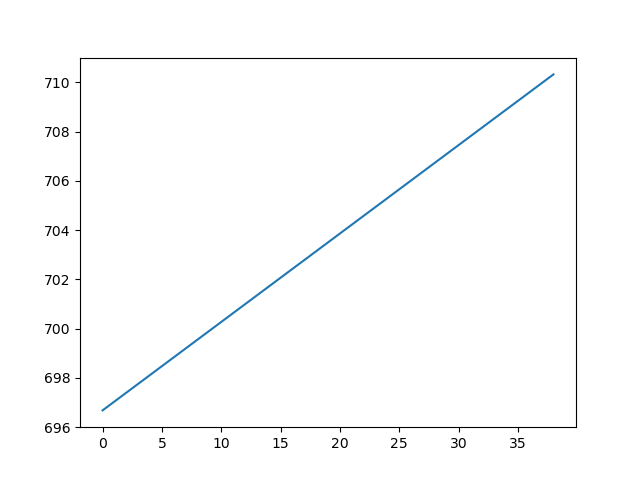

In [35]:
plt.figure()
plt.plot(svls['scanvar_on'])
plt.show()

### Emission Energy Calibration
- Based on the incident energy that has already been calibrated, find the elastic peak and fit linear line to it
- y = mx + b -> Emission Energy = m (emission pixel) + b